# BioSCRAPE Seesaw Simulation

This notebook illustrates the simulation of an AND-OR-NOT circuit with six NAND gates, consisting of 520 component DNAbased
circuit, that executes cellular automata transition functions ([Thubagere et al. *Nature Communications* 2017](https://www.nature.com/articles/ncomms14373)), using BioSCRAPE. The SBML file was obtained from [SeesawCompiler](https://qianlab.caltech.edu/SeesawCompiler/).

## Global variables, definitions, and dependencies

In [1]:
from bioscrape.simulator import py_simulate_model
from bioscrape.types import Model
import pylab as plt
from pathlib import Path
import numpy as np

#Get directory
# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()
model_dir = (base_dir / 'models').as_posix()

In [2]:
# Simulate all models - example for 12 hours
timepoints = np.linspace(0,12,4001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (8.27, 6) #in

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name):
    fs = 22
    plt.legend(title='Output',frameon=False, 
               title_fontsize = fs, fontsize=fs)
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=22)
    plt.xlim(0,12)

    plt.ylim(0,5*10**-8)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)

    # Save plot as svg
    plt.savefig(f'{figs_dir}/SI_{fig_name}.svg')

## Run Full Simulation (as is)

c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:183: UserWarning: SBML model contains reversible reaction!
Please check rate expressions and ensure they are non-negative before doing stochastic simulations.
  warnings.warn('SBML model contains reversible reaction!\n' +
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:56: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


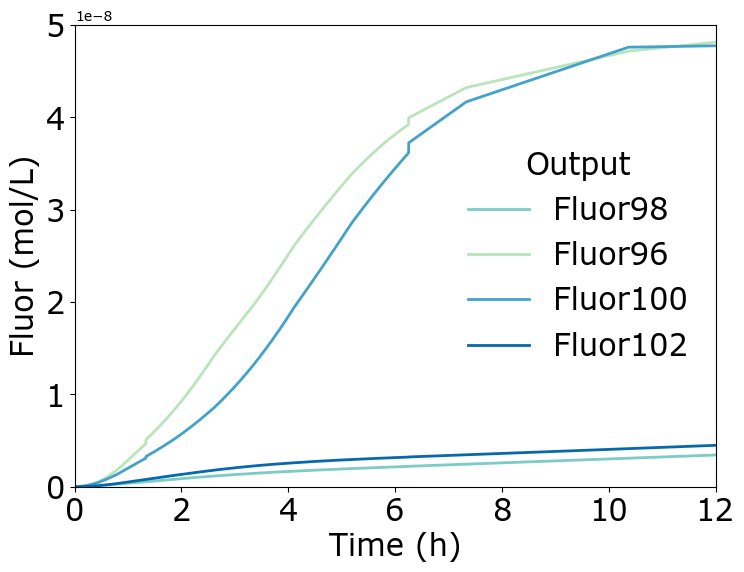

In [3]:
# Get model
filename = '/seesaw_sbml' #AND-OR circuit (150 species)
m = Model(sbml_filename = model_dir+filename+".xml")

# Simulate
R = py_simulate_model(Model  = m, timepoints = timepoints)
R.to_csv(f'{data_dir}/SI_seesaw_results.csv')

# Plot
colors={'Fluor96':'#bae4bc','Fluor98':'#7bccc4','Fluor100':'#43a2ca','Fluor102':'#0868ac'}

for x in ['Fluor98','Fluor96','Fluor100','Fluor102']: 
    plt.plot(R['time']/3600, R[x], linewidth = 2, label = x, color = colors[x])

FormatPlot('Fluor (mol/L)', 'BioSCRAPE_seesaw2017')

# Computing environment

In [4]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

